# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


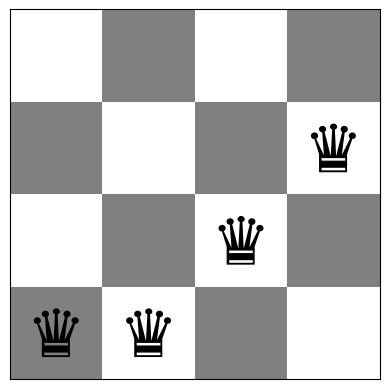

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [2]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


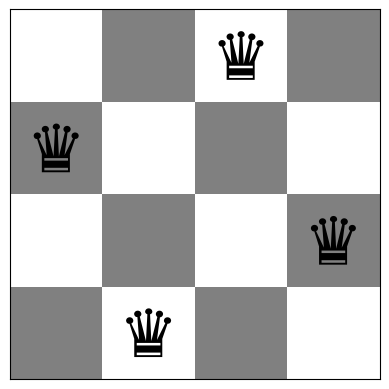

In [3]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

### Cài đặt

**Ý tưởng.** Trạng thái là vector `board` (mỗi cột đúng một quân hậu, `board[c]` là hàng của quân hậu ở cột `c`). Ở mỗi bước, thuật toán đánh giá *toàn bộ* $n(n-1)$ nước đi cục bộ (đổi hàng của một quân hậu trong cột của nó), rồi chọn nước đi cho `conflicts` nhỏ nhất. Nếu có nhiều nước đi cùng tốt nhất thì chọn ngẫu nhiên một nước (tránh thiên lệch theo thứ tự duyệt). Thuật toán dừng khi không còn nước đi nào làm giảm `conflicts` (cực trị cục bộ) hoặc khi `conflicts = 0`.

Mỗi thuật toán trả về một dict gồm: bàn cờ cuối (`board`), giá trị cuối (`f`), số bước đã đi (`steps`), số lần gọi `conflicts()` (`evals`) và lịch sử `f` theo từng bước (`history`) để vẽ đồ thị hội tụ.

Bàn cờ ban đầu : [7 3 6 5 4 4 0 1]  (f = 9)
Bàn cờ kết quả : [7 3 7 2 4 6 0 5]  (f = 1, 4 bước, 280 lần đánh giá)
Board with 1 conflicts.


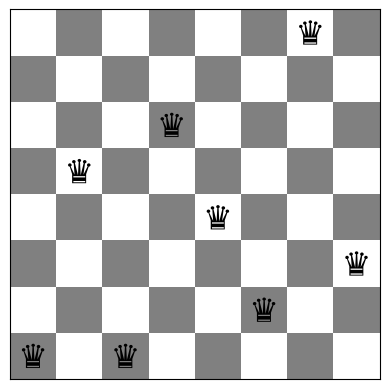

In [4]:
def steepest_ascent(board):
    """Steepest-ascent hill climbing: luôn chọn nước đi tốt nhất trong toàn bộ lân cận."""
    board = np.array(board).copy()
    n = len(board)
    f = conflicts(board)
    history, steps, evals = [f], 0, 0

    while f > 0:
        best_f, best_moves = f, []          # chỉ quan tâm các nước đi CẢI THIỆN f
        for c in range(n):
            old = board[c]
            for r in range(n):
                if r == old:
                    continue
                board[c] = r
                fn = conflicts(board); evals += 1
                if fn < best_f:
                    best_f, best_moves = fn, [(c, r)]
                elif fn == best_f and best_moves:
                    best_moves.append((c, r))
            board[c] = old                    # trả lại trạng thái cũ sau khi thử cột c

        if not best_moves:                    # không còn nước nào cải thiện -> cực trị cục bộ
            break
        c, r = best_moves[np.random.randint(len(best_moves))]
        board[c], f = r, best_f
        steps += 1
        history.append(f)

    return {"board": board, "f": f, "steps": steps, "evals": evals, "history": history}

# Ví dụ trên bàn cờ 8x8
np.random.seed(1234)
b0 = random_board(8)
res = steepest_ascent(b0)
print(f"Bàn cờ ban đầu : {b0}  (f = {conflicts(b0)})")
print(f"Bàn cờ kết quả : {res['board']}  (f = {res['f']}, {res['steps']} bước, {res['evals']} lần đánh giá)")
show_board(res["board"], fontsize=24)

**Nhận xét.** Steepest-ascent mỗi bước phải đánh giá $n(n-1)$ lân cận (với $n=8$ là 56 lần gọi `conflicts()`), nhưng đi theo hướng tốt nhất nên thường cần rất ít bước. Nhược điểm là thuật toán *tất định theo hướng đi* (chỉ ngẫu nhiên khi hòa) nên rất dễ mắc kẹt ở cực trị cục bộ – xem tỉ lệ thành công ở Task 6.

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [5]:
def stochastic_hill_climbing(board):
    """Inefficient stochastic HC: liệt kê MỌI nước đi cải thiện, rồi chọn ngẫu nhiên một nước."""
    board = np.array(board).copy()
    n = len(board)
    f = conflicts(board)
    history, steps, evals = [f], 0, 0

    while f > 0:
        improving = []                        # danh sách (cột, hàng mới, f mới) của các nước đi tốt hơn hiện tại
        for c in range(n):
            old = board[c]
            for r in range(n):
                if r == old:
                    continue
                board[c] = r
                fn = conflicts(board); evals += 1
                if fn < f:
                    improving.append((c, r, fn))
            board[c] = old
        if not improving:                     # cực trị cục bộ
            break
        c, r, fn = improving[np.random.randint(len(improving))]
        board[c], f = r, fn
        steps += 1
        history.append(f)

    return {"board": board, "f": f, "steps": steps, "evals": evals, "history": history}

np.random.seed(1234)
res = stochastic_hill_climbing(random_board(8))
print(f"f cuối = {res['f']}, {res['steps']} bước, {res['evals']} lần đánh giá conflicts()")

f cuối = 0, 6 bước, 336 lần đánh giá conflicts()


**Nhận xét.** Khác steepest-ascent ở chỗ nước đi được chọn *ngẫu nhiên trong tập các nước cải thiện* chứ không phải nước tốt nhất, nên đường đi đa dạng hơn (cần nhiều bước hơn, nhưng có thể tránh một số ngõ cụt). Chi phí đánh giá mỗi bước vẫn là $n(n-1)$ lần gọi `conflicts()` nên rất tốn kém – đó là lý do cần thuật toán ở Task 3.

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

### Cài đặt và chọn ngưỡng dừng $x$

Mỗi lần chỉ sinh **một** lân cận ngẫu nhiên (chọn cột ngẫu nhiên, chọn hàng mới ngẫu nhiên khác hàng hiện tại) và chấp nhận nếu `conflicts` giảm ngặt. Vì không bao giờ duyệt hết lân cận nên phải dùng tiêu chí dừng: *dừng nếu `x` lần thử liên tiếp không cải thiện*.

**Chọn $x$.** Tổng số lân cận là $N = n(n-1)$. Việc lấy mẫu có hoàn lại để "gần như chắc chắn" thử hết $N$ lân cận giống bài toán *coupon collector*: sau $N(\ln N + c)$ lần thử, xác suất đã thử mọi lân cận xấp xỉ $e^{-e^{-c}}$. Chọn $c = 2$ cho xác suất $\approx 87\%$:

$$x = \lceil N(\ln N + 2) \rceil, \qquad N = n(n-1)$$

(ví dụ $n=8$: $N=56$, $x=338$; $n=4$: $N=12$, $x=54$). Khi $n$ tăng, $x$ tăng khoảng $n^2 \ln n$.

In [6]:
def patience(n, c=2):
    """Số lần thử liên tiếp không cải thiện trước khi dừng (xem giải thích ở trên)."""
    N = n * (n - 1)
    return int(np.ceil(N * (np.log(N) + c)))

def first_choice(board, max_fail=None):
    """Efficient stochastic HC (first-choice): sinh một lân cận ngẫu nhiên, nhận nếu tốt hơn."""
    board = np.array(board).copy()
    n = len(board)
    if max_fail is None:
        max_fail = patience(n)
    f = conflicts(board)
    history, steps, evals, fails = [f], 0, 0, 0   # history ghi lại f sau MỖI lần thử

    while f > 0 and fails < max_fail:
        c = np.random.randint(n)
        r = np.random.randint(n - 1)
        r += (r >= board[c])                     # chọn hàng mới khác hàng hiện tại, đều trong n-1 hàng còn lại
        old = board[c]
        board[c] = r
        fn = conflicts(board); evals += 1
        if fn < f:                               # chấp nhận nếu tốt hơn
            f, fails = fn, 0
            steps += 1
        else:
            board[c] = old
            fails += 1
        history.append(f)

    return {"board": board, "f": f, "steps": steps, "evals": evals, "history": history}

np.random.seed(1234)
res = first_choice(random_board(8))
print(f"patience(8) = {patience(8)}, patience(4) = {patience(4)}")
print(f"f cuối = {res['f']}, {res['steps']} nước đi được nhận, {res['evals']} lần đánh giá conflicts()")

patience(8) = 338, patience(4) = 54
f cuối = 1, 6 nước đi được nhận, 388 lần đánh giá conflicts()


**Nhận xét.** Với cùng một bàn cờ ban đầu, first-choice cho kết quả cùng loại với Task 2 (cùng dừng ở cực trị cục bộ khi không còn nước cải thiện) nhưng mỗi bước chỉ tốn 1 lần đánh giá thay vì $n(n-1)$. Điểm yếu là cực trị cục bộ chỉ được phát hiện *xác suất* (qua ngưỡng $x$) chứ không chắc chắn.

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [7]:
def random_restart(algo, n, max_restarts=100):
    """Chạy lại thuật toán `algo` từ các bàn cờ ngẫu nhiên mới, tối đa max_restarts lần.
    Dừng sớm khi tìm được lời giải (f = 0); trả về kết quả tốt nhất cùng tổng chi phí."""
    best, total_steps, total_evals = None, 0, 0
    for k in range(1, max_restarts + 1):
        r = algo(random_board(n))
        total_steps += r["steps"]; total_evals += r["evals"]
        if best is None or r["f"] < best["f"]:
            best = r
        if r["f"] == 0:
            break
    return {**best, "steps": total_steps, "evals": total_evals, "restarts": k}

import pandas as pd
rows = []
for name, algo in [("Steepest-ascent", steepest_ascent),
                   ("Stochastic HC (mọi nước đi)", stochastic_hill_climbing),
                   ("First-choice HC", first_choice)]:
    for n in (4, 8):
        np.random.seed(2024)
        R_ = [random_restart(algo, n) for _ in range(100)]
        rows.append({"Thuật toán": name + " + restart", "n": n,
                     "% tìm được f=0 trong ≤100 lần": 100 * np.mean([r["f"] == 0 for r in R_]),
                     "TB số lần khởi động": np.mean([r["restarts"] for r in R_]),
                     "Max số lần khởi động": max(r["restarts"] for r in R_)})
pd.DataFrame(rows).round(2)

,Thuật toán,n,% tìm được f=0 trong ≤100 lần,TB số lần khởi động,Max số lần khởi động
0,Steepest-ascent + restart,4,100.0,2.32,15
1,Steepest-ascent + restart,8,100.0,7.90,28
2,Stochastic HC (mọi nước đi) + restart,4,100.0,2.89,14
3,Stochastic HC (mọi nước đi) + restart,8,100.0,6.94,45
4,First-choice HC + restart,4,100.0,2.65,12
5,First-choice HC + restart,8,100.0,8.69,51


**Nhận xét.** Random restart biến một thuật toán hay mắc kẹt thành thuật toán gần như luôn thành công: nếu một lần chạy đơn thành công với xác suất $p$ thì số lần khởi động cần thiết có kỳ vọng $\approx 1/p$. Với $n=8$, steepest-ascent chỉ thành công khoảng 19% mỗi lần chạy đơn (Task 6) nên cần trung bình vài lần khởi động (kỳ vọng $\approx 1/p$; bảng trên cho số liệu thực nghiệm: khoảng 7-9 lần khi $n=8$); 100 lần khởi động là dư dả. Việc tăng thêm số lần restart chỉ có ích khi $p$ rất nhỏ; nếu $p$ đã đủ lớn, mỗi lần restart thêm chỉ làm tăng chi phí mà không cải thiện kết quả.

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

### Lịch giảm nhiệt độ

Dùng các lịch trong notebook `Simulated_Annealing_Schedules.ipynb` (với $T_0$ là nhiệt độ ban đầu và $t \ge 1$ là chỉ số vòng lặp):

* Mũ: $T(t) = T_0\,\alpha^t$
* Tuyến tính: $T(t) = T_0 - \eta t$
* Fast: $T(t) = T_0/(1+t)$
* Logarithmic: $T(t) = T_0/\ln(1+t)$

**Simulated annealing cho n-Queens.** Mỗi vòng lặp sinh một lân cận ngẫu nhiên (như first-choice). Với $\Delta = f(\text{mới}) - f(\text{hiện tại})$: nếu $\Delta < 0$ thì chấp nhận; nếu $\Delta \ge 0$ thì chấp nhận với xác suất $p = e^{-\Delta/T}$. Dừng khi $f=0$, khi $T < T_{min}$ hoặc hết số vòng lặp tối đa (`max_iter`).

In [8]:
def temperature_exponential(t, T0, alpha): return T0 * alpha ** t
def temperature_linear(t, T0, eta):        return T0 - eta * t
def temperature_fast(t, T0):               return T0 / (1 + t)
def temperature_logarithmic(t, T0):        return T0 / np.log1p(t)

def simulated_annealing(board, schedule, max_iter=5000, T_min=1e-3):
    """schedule: hàm t -> T(t) (t = 1, 2, ...). Trả về dict như các thuật toán trước.
    history ghi f hiện tại sau mỗi vòng lặp; 'best_f' là giá trị tốt nhất từng gặp."""
    board = np.array(board).copy()
    n = len(board)
    f = conflicts(board)
    best_f, best_board = f, board.copy()
    history, steps, evals = [f], 0, 0

    for t in range(1, max_iter + 1):
        T = schedule(t)
        if T < T_min:                             # đã "nguội" hoàn toàn
            break
        c = np.random.randint(n)
        r = np.random.randint(n - 1); r += (r >= board[c])
        old = board[c]; board[c] = r
        fn = conflicts(board); evals += 1
        delta = fn - f
        if delta < 0 or np.random.rand() < np.exp(-delta / T):   # luật chấp nhận Metropolis
            f = fn; steps += 1
            if f < best_f:
                best_f, best_board = f, board.copy()
        else:
            board[c] = old
        history.append(f)
        if f == 0:
            break

    return {"board": best_board, "f": best_f, "steps": steps, "evals": evals, "history": history}

# Các cấu hình lịch nhiệt độ để khảo sát (T0 = 2: chênh lệch f giữa các lân cận thường cỡ 1-3)
SCHEDULES = {
    "Mũ α=0.9":    lambda t: temperature_exponential(t, 2, 0.9),
    "Mũ α=0.99":   lambda t: temperature_exponential(t, 2, 0.99),
    "Mũ α=0.999":  lambda t: temperature_exponential(t, 2, 0.999),
    "Tuyến tính η=0.001":  lambda t: temperature_linear(t, 2, 0.001),
    "Tuyến tính η=0.0004": lambda t: temperature_linear(t, 2, 0.0004),
    "Fast":        lambda t: temperature_fast(t, 2),
    "Logarithmic": lambda t: temperature_logarithmic(t, 2),
}
DEFAULT_SA = SCHEDULES["Mũ α=0.999"]      # lịch dùng mặc định ở Task 6

### Trực quan hóa quá trình tìm kiếm và khảo sát lịch nhiệt độ

Biểu đồ bên trái: một lần chạy (cùng bàn cờ ban đầu 8x8, cùng seed) cho mỗi lịch nhiệt độ; biểu đồ bên phải: đường nhiệt độ $T(t)$ tương ứng.

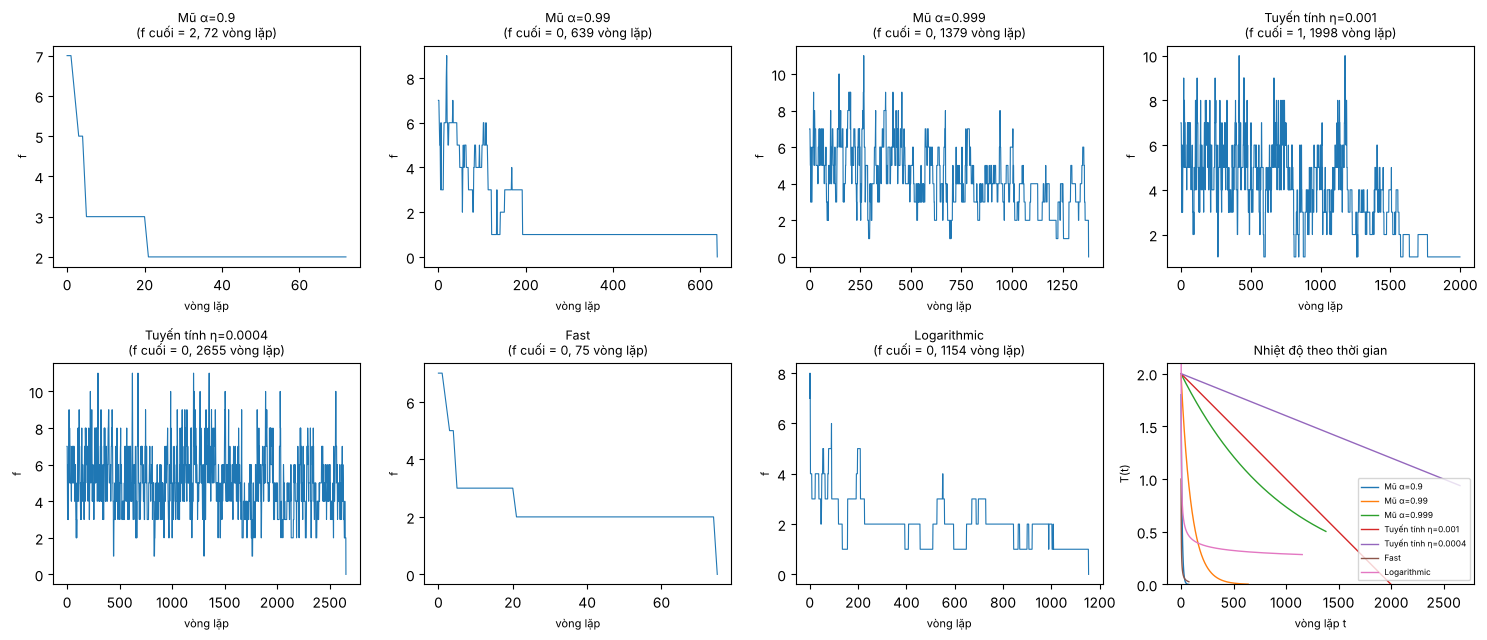

,Lịch nhiệt độ,% thành công (f=0),TB f cuối,TB số vòng lặp,TB thời gian (ms)
0,Mũ α=0.9,7.0,1.63,70.87,0.96
1,Mũ α=0.99,60.0,0.40,529.71,7.71
2,Mũ α=0.999,98.0,0.02,1717.30,21.55
3,Tuyến tính η=0.001,67.0,0.33,1683.95,30.43
4,Tuyến tính η=0.0004,93.0,0.07,3296.29,52.38
5,Fast,88.0,0.12,732.82,11.30
6,Logarithmic,100.0,0.00,712.06,13.88


In [9]:
import time
np.random.seed(7)
b0 = random_board(8)

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
fig_axes = axes.ravel()
for k, (name, sch) in enumerate(SCHEDULES.items()):
    np.random.seed(11)
    res = simulated_annealing(b0, sch)
    fig_axes[k].plot(res["history"], lw=0.8)
    fig_axes[k].set_title(f"{name}\n(f cuối = {res['f']}, {res['evals']} vòng lặp)", fontsize=9)
    fig_axes[k].set_xlabel("vòng lặp", fontsize=8); fig_axes[k].set_ylabel("f", fontsize=8)
    tt = np.arange(1, max(len(res["history"]), 2))
    fig_axes[7].plot(tt, [sch(t) for t in tt], label=name, lw=1)
fig_axes[7].set_xlabel("vòng lặp t", fontsize=8); fig_axes[7].set_ylabel("T(t)", fontsize=8)
fig_axes[7].set_title("Nhiệt độ theo thời gian", fontsize=9); fig_axes[7].set_ylim(0, 2.1); fig_axes[7].legend(fontsize=6)
plt.tight_layout(); plt.show()

# Lặp 100 lần để so sánh các lịch một cách công bằng (n = 8)
rows = []
for name, sch in SCHEDULES.items():
    np.random.seed(5)
    R_ = []
    for _ in range(100):
        t0 = time.perf_counter(); r = simulated_annealing(random_board(8), sch); r["time"] = time.perf_counter() - t0; R_.append(r)
    rows.append({"Lịch nhiệt độ": name,
                 "% thành công (f=0)": 100 * np.mean([r["f"] == 0 for r in R_]),
                 "TB f cuối": np.mean([r["f"] for r in R_]),
                 "TB số vòng lặp": np.mean([r["evals"] for r in R_]),
                 "TB thời gian (ms)": 1e3 * np.mean([r["time"] for r in R_])})
sa_table = pd.DataFrame(rows).round(2)
sa_table

**Điều rút ra.**

* Giảm nhiệt quá nhanh (mũ $\alpha=0.9$) khiến thuật toán "đóng băng" sau vài chục vòng lặp: nó hành xử như hill climbing và thành công rất ít.
* Giảm chậm hơn ($\alpha=0.99 \to 0.999$, hoặc tuyến tính với $\eta$ nhỏ) cho phép khám phá lâu hơn bằng các bước xấu nên tỉ lệ thành công tăng lên gần 100%, nhưng phải trả giá bằng số vòng lặp và thời gian chạy lớn hơn.
* Lịch *fast* và *logarithmic* giảm rất nhanh lúc đầu rồi chậm dần (nhiệt độ còn "ấm" trong thời gian dài), phù hợp với bài toán này vì khoảng cách giữa các giá trị $f$ là số nguyên nhỏ; lịch logarithmic thường cho tỉ lệ thành công cao với số vòng lặp vừa phải.
* Nhiệt độ ban đầu nên cùng bậc với độ chênh $\Delta$ thường gặp (1-3). $T_0$ quá nhỏ làm mất giai đoạn khám phá; $T_0$ quá lớn lãng phí vòng lặp đầu ở trạng thái gần như đi ngẫu nhiên.

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

Bảng kết quả (100 lần chạy cho mỗi dòng, mỗi lần một bàn cờ ban đầu ngẫu nhiên khác nhau; số liệu lấy từ ô mã bên dưới, bảng đầy đủ hơn có thêm số bước và số lần đánh giá):

| Thuật toán | Kích thước bàn cờ | Thời gian chạy TB (ms) | Số xung đột TB | % số lần kết thúc ở lời giải tối ưu |
| --- | --- | --- | --- | --- |
| Steepest asc. HC | 4 | 0.10 | 0.57 | 47% |
| Ineff. Stochastic HC | 4 | 0.12 | 0.89 | 29% |
| Efficient Stochastic HC | 4 | 0.40 | 0.70 | 36% |
| Simulated Annealing | 4 | 0.99 | 0.00 | 100% |
| Steepest asc. HC + Restart | 4 | 0.32 | 0.00 | 100% |
| Steepest asc. HC | 8 | 1.64 | 1.20 | 19% |
| Ineff. Stochastic HC | 8 | 1.91 | 1.34 | 11% |
| Efficient Stochastic HC | 8 | 4.49 | 1.44 | 8% |
| Simulated Annealing | 8 | 28.78 | 0.01 | 99% |
| Steepest asc. HC + Restart | 8 | 11.55 | 0.00 | 100% |

(Thời gian chạy phụ thuộc cấu hình máy nên có thể sai khác giữa các lần chạy; các cột còn lại cố định nhờ seed.)

In [10]:
ALGOS = {
    "Steepest asc. HC":        steepest_ascent,
    "Ineff. Stochastic HC":    stochastic_hill_climbing,
    "Efficient Stochastic HC": first_choice,
    "Simulated Annealing":     lambda b: simulated_annealing(b, DEFAULT_SA),
    "Steepest asc. + Restart": lambda b: random_restart(steepest_ascent, len(b)),
}

def run_experiment(algo, n, runs=100, seed=0):
    """Chạy `algo` `runs` lần trên các bàn cờ ngẫu nhiên khác nhau (cố định seed để lặp lại được)."""
    np.random.seed(seed)
    out = {"time": [], "f": [], "steps": [], "evals": []}
    for _ in range(runs):
        b = random_board(n)
        t0 = time.perf_counter()
        r = algo(b)
        out["time"].append(time.perf_counter() - t0)
        for k in ("f", "steps", "evals"):
            out[k].append(r[k])
    return {k: np.array(v) for k, v in out.items()}

rows, results = [], {}
for n in (4, 8):
    for name, algo in ALGOS.items():
        r = run_experiment(algo, n, runs=100, seed=100 + n)
        results[(name, n)] = r
        rows.append({"Algorithm": name, "Board size": n,
                     "Avg. run time (ms)": 1e3 * r["time"].mean(),
                     "Avg. number of conflicts": r["f"].mean(),
                     "% of runs ending in optimal solution": 100 * np.mean(r["f"] == 0),
                     "Best f": int(r["f"].min()),
                     "Avg. steps": r["steps"].mean(),
                     "Avg. evaluations": r["evals"].mean()})
table6 = pd.DataFrame(rows).round(3)
table6

,Algorithm,Board size,Avg. run time (ms),Avg. number of conflicts,% of runs ending in optimal solution,Best f,Avg. steps,Avg. evaluations
0,Steepest asc. HC,4,0.100,0.57,47.0,0,1.49,24.24
1,Ineff. Stochastic HC,4,0.121,0.89,29.0,0,1.79,30.00
2,Efficient Stochastic HC,4,0.395,0.70,36.0,0,1.81,45.84
3,Simulated Annealing,4,0.992,0.00,100.0,0,72.46,97.77
4,Steepest asc. + Restart,4,0.319,0.00,100.0,0,4.07,66.72
5,Steepest asc. HC,8,1.639,1.20,19.0,0,3.33,231.84
6,Ineff. Stochastic HC,8,1.905,1.34,11.0,0,5.08,334.32
7,Efficient Stochastic HC,8,4.489,1.44,8.0,0,4.79,374.49
8,Simulated Annealing,8,28.782,0.01,99.0,0,655.91,1640.66
9,Steepest asc. + Restart,8,11.552,0.00,100.0,0,24.72,1762.88


**Nhận xét bảng kết quả (100 lần chạy, mỗi lần một bàn cờ ngẫu nhiên khác nhau).**

* Các thuật toán leo đồi thuần túy (steepest, stochastic, first-choice) có tỉ lệ thành công thấp, đặc biệt khi $n=8$ (chỉ khoảng 8-19%), do bị mắc kẹt ở cực trị cục bộ.
* Simulated annealing (lịch mũ $\alpha=0.999$) gần như luôn tìm được lời giải nhưng chậm hơn các thuật toán leo đồi một lần chạy vì phải thực hiện hàng nghìn vòng lặp.
* Steepest-ascent + random restart đạt 100% thành công và nhanh hơn SA trên bài toán $n=8$ vì mỗi lần leo đồi rất rẻ (vài bước).
* Với $n=4$ không gian trạng thái rất nhỏ ($4^4 = 256$ bàn cờ) nên mọi thuật toán đều nhanh; sự khác biệt chủ yếu nằm ở tỉ lệ thành công.

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

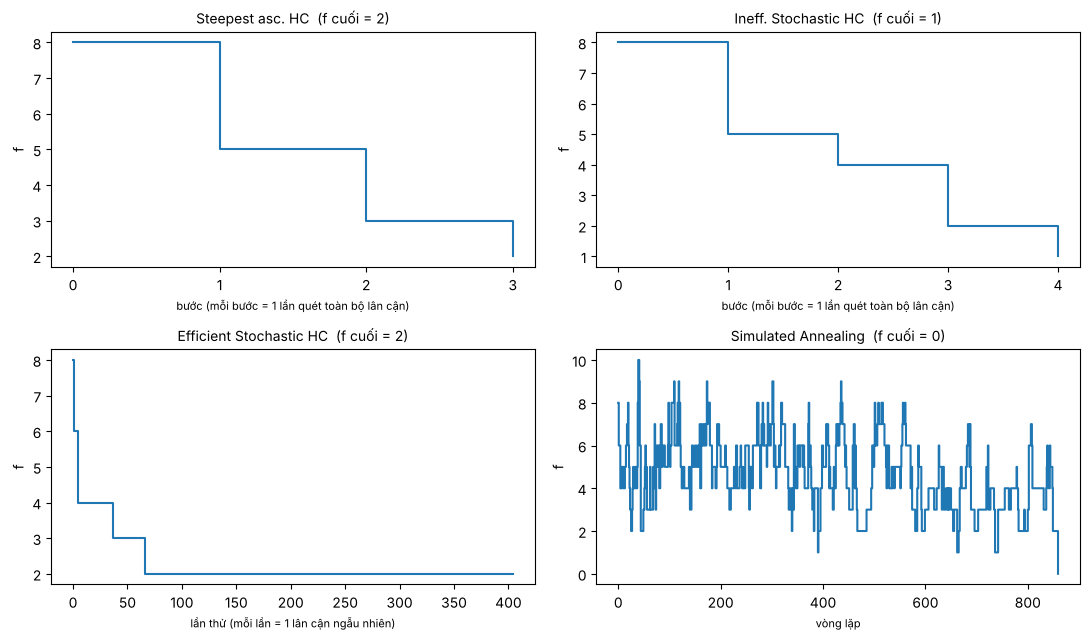

% lần chạy kết thúc ở cực trị cục bộ (n = 8): {'Steepest asc. HC': 81.0, 'Ineff. Stochastic HC': 89.0, 'Efficient Stochastic HC': 92.0, 'Simulated Annealing': 1.0}


In [11]:
# Một lần chạy đại diện của từng thuật toán trên bài toán 8 quân hậu (cùng bàn cờ ban đầu)
np.random.seed(21)
b0 = random_board(8)
reps = {}
for name, algo in list(ALGOS.items())[:4]:
    np.random.seed(33)
    reps[name] = algo(b0)

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
xlabel = {"Steepest asc. HC": "bước (mỗi bước = 1 lần quét toàn bộ lân cận)",
          "Ineff. Stochastic HC": "bước (mỗi bước = 1 lần quét toàn bộ lân cận)",
          "Efficient Stochastic HC": "lần thử (mỗi lần = 1 lân cận ngẫu nhiên)",
          "Simulated Annealing": "vòng lặp"}
for ax, (name, r) in zip(axes.ravel(), reps.items()):
    ax.step(range(len(r["history"])), r["history"], where="post")
    ax.xaxis.get_major_locator().set_params(integer=True); ax.yaxis.get_major_locator().set_params(integer=True)
    ax.set_title(f"{name}  (f cuối = {r['f']})", fontsize=10)
    ax.set_xlabel(xlabel[name], fontsize=8); ax.set_ylabel("f")
plt.tight_layout(); plt.show()

# Tỉ lệ các lần chạy bị kẹt (kết thúc với f > 0) trên n = 8
stuck = {name: 100 * np.mean(results[(name, 8)]["f"] > 0) for name in list(ALGOS)[:4]}
print("% lần chạy kết thúc ở cực trị cục bộ (n = 8):", {k: float(round(v, 1)) for k, v in stuck.items()})

**Dạng hội tụ điển hình.**

* *Steepest-ascent* và *stochastic HC*: $f$ giảm rất nhanh ở những bước đầu (mỗi bước bỏ đi nhiều xung đột) rồi đi ngang thành một "bậc thang" phẳng ở giá trị $f>0$ khi bị kẹt tại cực trị cục bộ – đây là hai thuật toán hay bị kẹt nhất.
* *First-choice*: đường $f$ có dạng bậc thang dài vì phần lớn các lần thử bị từ chối; nó chỉ dừng sau khi thử đủ $x$ lần liên tiếp mà không cải thiện, nên cũng thường bị kẹt (có thể gặp plateau – các lân cận có cùng $f$ không được chấp nhận vì dùng so sánh ngặt).
* *Simulated annealing*: $f$ dao động mạnh trong suốt giai đoạn nhiệt độ còn cao (chấp nhận nhiều bước xấu, thỉnh thoảng chạm các giá trị thấp rồi lại bị đẩy lên), và thuật toán dừng khi bắt gặp $f=0$. Nó ít khi bị kẹt hơn rõ rệt so với các thuật toán leo đồi (xem tỉ lệ in ra ở trên) vì có thể thoát khỏi cực trị cục bộ bằng các bước đi xấu.

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

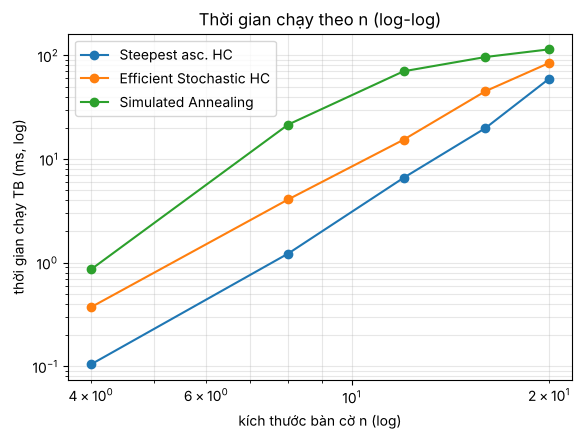

,Thuật toán,k ước lượng (mọi n),k ước lượng (n ≥ 12),t(n=4) ms,t(n=8) ms,t(n=12) ms,t(n=16) ms,t(n=20) ms,%succ n=4,%succ n=8,%succ n=12,%succ n=16,%succ n=20
0,Steepest asc. HC,3.91,4.28,0.10,1.22,6.58,19.86,59.29,43.333333,3.333333,6.666667,3.333333,3.333333
1,Efficient Stochastic HC,3.40,3.35,0.37,4.07,15.34,45.07,84.22,36.666667,6.666667,6.666667,0.000000,0.000000
2,Simulated Annealing,3.08,0.96,0.86,21.48,70.17,96.32,114.17,100.000000,100.000000,83.333333,70.000000,36.666667


In [12]:
# Khả năng mở rộng: thời gian chạy theo kích thước bàn cờ n = 4, 8, 12, 16, 20
sizes = [4, 8, 12, 16, 20]
scal_algos = {
    "Steepest asc. HC":        steepest_ascent,
    "Efficient Stochastic HC": first_choice,
    "Simulated Annealing":     lambda b: simulated_annealing(b, DEFAULT_SA),
}
scal = {name: {"time": [], "succ": []} for name in scal_algos}
for n in sizes:
    for name, algo in scal_algos.items():
        r = run_experiment(algo, n, runs=30, seed=500 + n)
        scal[name]["time"].append(1e3 * r["time"].mean())
        scal[name]["succ"].append(100 * np.mean(r["f"] == 0))

plt.figure(figsize=(6.5, 4.5))
slopes, slopes_big = {}, {}
for name, d in scal.items():
    plt.loglog(sizes, d["time"], "o-", label=name)
    slopes[name] = np.polyfit(np.log(sizes), np.log(d["time"]), 1)[0]   # hệ số góc ≈ số mũ k trong O(n^k)
    slopes_big[name] = np.polyfit(np.log(sizes[2:]), np.log(d["time"][2:]), 1)[0]   # chỉ dùng n >= 12
plt.xlabel("kích thước bàn cờ n (log)"); plt.ylabel("thời gian chạy TB (ms, log)")
plt.title("Thời gian chạy theo n (log-log)"); plt.legend(); plt.grid(True, which="both", alpha=0.3)
plt.show()

pd.DataFrame({
    "Thuật toán": list(scal),
    "k ước lượng (mọi n)": [round(slopes[k], 2) for k in scal],
    "k ước lượng (n ≥ 12)": [round(slopes_big[k], 2) for k in scal],
    **{f"t(n={n}) ms": [round(scal[k]["time"][i], 2) for k in scal] for i, n in enumerate(sizes)},
    **{f"%succ n={n}": [scal[k]["succ"][i] for k in scal] for i, n in enumerate(sizes)},
})

**Ước lượng độ phức tạp thực nghiệm.** Độ dốc của đường thẳng trong đồ thị log-log cho số mũ $k$ trong $t \sim n^k$ (bảng có hai cột: ước lượng trên mọi $n$ và chỉ trên $n \ge 12$). Lưu ý: $k$ được ước lượng từ 5 điểm đo và thời gian đo có nhiễu, nên giữa các lần chạy notebook $k$ có thể dao động khoảng $\pm 0.3$; chỉ nên đọc như xu hướng.

* *Steepest-ascent*: mỗi bước đánh giá $n(n-1)$ lân cận, mỗi lần gọi `conflicts()` tốn $O(n)$ nên một bước tốn $O(n^3)$; số bước cần thiết cũng tăng theo $n$. Thực nghiệm cho $k \approx 3.9\text{-}4.3$ – mở rộng kém nhất.
* *First-choice*: mỗi lần thử chỉ tốn $O(n)$ nhưng ngưỡng dừng $x \approx n^2 \ln n$ nên khi bị kẹt tổng chi phí khoảng $O(n^3 \log n)$; thực nghiệm $k \approx 3.4$.
* *Simulated annealing*: số vòng lặp tối đa cố định (5000) và mỗi vòng $O(n)$, nên với $n$ lớn (khi hầu hết các lần chạy dùng hết ngân sách) thời gian tăng gần tuyến tính theo $n$ ($k \approx 1.0$ trên $n \ge 12$). Ước lượng "mọi $n$" cao hơn (khoảng 3.1) vì ở $n$ nhỏ SA dừng sớm khi tìm được lời giải nên thời gian ngắn hơn hẳn.

**Kết luận và lưu ý.** SA mở rộng tốt nhất về thời gian trên mỗi lần chạy. Tuy nhiên đó chưa phải là tất cả: với ngân sách cố định, tỉ lệ thành công của SA giảm khi $n$ tăng (cột `%succ`), còn các thuật toán leo đồi hầu như luôn bị kẹt ở $n \ge 8$ (thành công chỉ vài %), tức là chúng "nhanh" nhưng cho lời giải sai. Muốn SA giải được bàn cờ lớn cần tăng số vòng lặp tối đa theo $n$.

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

### Cài đặt các toán tử di chuyển

Mỗi toán tử nhận bàn cờ hiện tại và trả về *một bàn cờ ứng viên mới* (không sửa bàn cờ cũ). Thuật toán dùng chung là first-choice hill climbing: chấp nhận ứng viên nếu `conflicts` giảm ngặt, chạy tối đa `max_iter` lần thử và dừng sớm khi $f=0$.

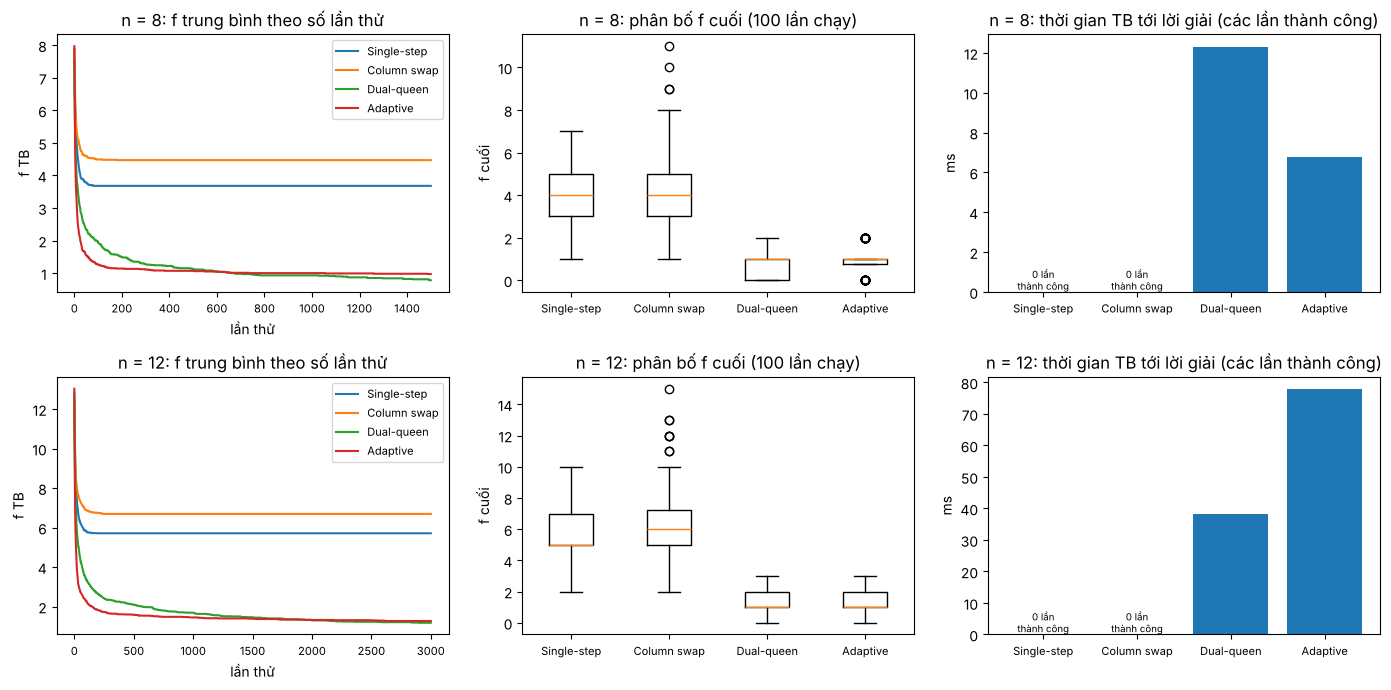

,n,Toán tử,% thành công,TB f cuối,TB thời gian thành công (ms)
0,8,Single-step,0.0,3.68,NaN
1,8,Column swap,0.0,4.47,NaN
2,8,Dual-queen,30.0,0.78,12.31
3,8,Adaptive,25.0,0.97,6.79
4,12,Single-step,0.0,5.71,NaN
5,12,Column swap,0.0,6.69,NaN
6,12,Dual-queen,12.0,1.18,38.37
7,12,Adaptive,10.0,1.27,77.82


In [13]:
def op_single_step(board):
    """Dịch MỘT quân hậu lên hoặc xuống đúng một ô."""
    n = len(board); new = board.copy()
    while True:
        c = np.random.randint(n); r = new[c] + np.random.choice([-1, 1])
        if 0 <= r < n:
            new[c] = r; return new

def op_column_swap(board):
    """Hoán đổi hàng của hai quân hậu ở hai cột ngẫu nhiên khác nhau."""
    n = len(board); new = board.copy()
    i, j = np.random.choice(n, 2, replace=False)
    new[i], new[j] = new[j], new[i]
    return new

def op_dual_queen(board):
    """Chọn hai quân hậu và chuyển cả hai đến hàng ngẫu nhiên mới cùng lúc."""
    n = len(board); new = board.copy()
    for c in np.random.choice(n, 2, replace=False):
        new[c] = np.random.randint(n)
    return new

def queen_conflicts(board):
    """Số quân hậu khác đang tấn công từng quân hậu (O(n^2), chỉ dùng cho toán tử adaptive)."""
    n = len(board)
    return np.array([sum(1 for j in range(n) if j != i and (board[j] == board[i] or abs(board[j] - board[i]) == abs(j - i)))
                     for i in range(n)])

def op_adaptive(board):
    """Toán tử thích nghi: nếu còn xung đột thì với xác suất 0.7 di chuyển quân hậu đang bị xung đột
    NHIỀU NHẤT sang hàng ngẫu nhiên; ngược lại chọn ngẫu nhiên một trong ba toán tử trên."""
    n = len(board)
    qc = queen_conflicts(board)
    if qc.max() > 0 and np.random.rand() < 0.7:
        worst = np.flatnonzero(qc == qc.max())
        c = np.random.choice(worst)
        new = board.copy(); new[c] = np.random.randint(n)
        return new
    return np.random.choice([op_single_step, op_column_swap, op_dual_queen])(board)

OPERATORS = {"Single-step": op_single_step, "Column swap": op_column_swap,
             "Dual-queen": op_dual_queen, "Adaptive": op_adaptive}

def first_choice_op(board, op, max_iter):
    """First-choice HC với toán tử `op`. Trả về lịch sử f (độ dài max_iter+1), f cuối và số lần thử."""
    board = np.array(board).copy(); f = conflicts(board)
    hist = np.full(max_iter + 1, f, dtype=float); tries = 0
    for t in range(1, max_iter + 1):
        if f == 0:
            hist[t:] = 0; break
        cand = op(board); fc = conflicts(cand); tries = t
        if fc < f:
            board, f = cand, fc
        hist[t] = f
    return {"hist": hist, "f": f, "tries": tries}

adv = {}
for n, max_iter in ((8, 1500), (12, 3000)):
    for name, op in OPERATORS.items():
        np.random.seed(77)
        R_ = []
        for _ in range(100):
            t0 = time.perf_counter(); r = first_choice_op(random_board(n), op, max_iter); r["time"] = time.perf_counter() - t0
            R_.append(r)
        adv[(n, name)] = R_

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for row, n in enumerate((8, 12)):
    for name in OPERATORS:
        R_ = adv[(n, name)]
        axes[row, 0].plot(np.mean([r["hist"] for r in R_], axis=0), label=name)
    axes[row, 0].set_title(f"n = {n}: f trung bình theo số lần thử"); axes[row, 0].set_xlabel("lần thử"); axes[row, 0].set_ylabel("f TB"); axes[row, 0].legend(fontsize=8)
    axes[row, 1].boxplot([[r["f"] for r in adv[(n, name)]] for name in OPERATORS])
    axes[row, 1].set_xticklabels(list(OPERATORS))
    axes[row, 1].set_title(f"n = {n}: phân bố f cuối (100 lần chạy)"); axes[row, 1].set_ylabel("f cuối")
    tt = [1e3 * np.mean([r["time"] for r in adv[(n, name)] if r["f"] == 0] or [np.nan]) for name in OPERATORS]
    axes[row, 2].bar(list(OPERATORS), np.nan_to_num(tt))
    for k, name in enumerate(OPERATORS):
        if np.isnan(tt[k]):
            axes[row, 2].text(k, 0, "0 lần\nthành công", ha="center", va="bottom", fontsize=7)
    axes[row, 2].set_title(f"n = {n}: thời gian TB tới lời giải (các lần thành công)"); axes[row, 2].set_ylabel("ms")
for ax in axes.ravel(): ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

pd.DataFrame([{"n": n, "Toán tử": name,
               "% thành công": 100 * np.mean([r["f"] == 0 for r in adv[(n, name)]]),
               "TB f cuối": np.mean([r["f"] for r in adv[(n, name)]]),
               "TB thời gian thành công (ms)": 1e3 * np.mean([r["time"] for r in adv[(n, name)] if r["f"] == 0] or [np.nan])}
              for n in (8, 12) for name in OPERATORS]).round(2)

### Thảo luận

Kết quả đo được (100 lần chạy, first-choice với ngân sách cố định 1500 lần thử cho $n=8$ và 3000 lần cho $n=12$; xem bảng và biểu đồ phía trên):

* *Single-step* (dịch 1 ô) và *Column swap* đều **không giải được** lần nào. Single-step chỉ nhìn một lân cận rất nhỏ nên bị kẹt ở cực trị cục bộ rất sớm. Column swap có lý do cấu trúc: hoán đổi hàng của hai quân hậu giữ nguyên *tập* các hàng đang dùng, do đó nếu bàn cờ ban đầu (ngẫu nhiên) có hai quân cùng hàng thì xung đột hàng không bao giờ mất đi; toán tử này chỉ phù hợp khi khởi tạo từ một hoán vị (mỗi hàng đúng một quân), khi đó không gian tìm kiếm co lại còn $n!$ trạng thái.
* *Dual-queen* (di chuyển hai quân hậu cùng lúc tới hàng ngẫu nhiên) tốt nhất ở cả hai cỡ bàn cờ: tỉ lệ thành công cao nhất (khoảng 30% với $n=8$ và 12% với $n=12$) và $f$ cuối trung bình thấp nhất. Bước nhảy lớn hơn cho phép vượt qua một số cực trị cục bộ mà một nước đi đơn lẻ không thoát được.
* *Adaptive* (tập trung vào quân hậu đang bị xung đột nhiều nhất, hoặc chọn ngẫu nhiên một toán tử khác) cho chất lượng gần với dual-queen nhưng không vượt qua nó trong thí nghiệm này, Về thời gian, kết quả phụ thuộc kích thước: với $n=8$ các lần chạy thành công của adaptive còn *nhanh hơn* dual-queen (khoảng 6.8 so với 12.3 ms) vì nhắm đúng quân hậu đang gây xung đột nên tới lời giải sau ít lần thử hơn; nhưng với $n=12$ nó *chậm hơn* khoảng gấp đôi (77.8 so với 38.4 ms) vì mỗi lần thử phải tính xung đột của từng quân ($O(n^2)$), chi phí này tăng nhanh theo $n$. Ngoài ra, vì chỉ chấp nhận cải thiện ngặt nên adaptive vẫn bị kẹt như các toán tử khác.
* Bài học chung: tập lân cận càng *rộng/đa dạng* thì khả năng thoát cực trị cục bộ càng cao, nhưng mỗi ứng viên càng ít khả năng tốt hơn; và toán tử phải *phù hợp với biểu diễn trạng thái* (column swap chỉ hợp với biểu diễn hoán vị). Để thoát cực trị hiệu quả hơn nữa cần cơ chế khác như random restart hay simulated annealing.

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [14]:
# Code and description go here